In [1]:
import torch
from sklearn.metrics import r2_score
from torch import nn
from torch.utils.data import Dataset, DataLoader, random_split
from sklearn.metrics import root_mean_squared_error, precision_score, recall_score, f1_score
import pandas as pd

In [2]:
device = torch.accelerator.current_accelerator().type if torch.accelerator.is_available() else 'cpu'
device

'cuda'

# Регрессия

In [3]:
class DiamondsDataset(Dataset):
    def __init__(self, data_dir):
        df = pd.read_csv(data_dir, index_col=0)
        self.features = df.drop(columns=['price']).astype("float32").to_numpy()
        self.labels = df['price'].astype("float32").to_numpy()

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        X = torch.tensor(self.features[idx])
        y = torch.tensor(self.labels[idx])
        return X, y

In [4]:
diamonds_ds = DiamondsDataset(r'../data/diamonds_filtered.csv')

In [5]:
batch_size = 64

In [6]:
train_data_diam, test_data_diam = random_split(diamonds_ds, [0.8, 0.2])
train_dataloader_diam = DataLoader(train_data_diam, batch_size=batch_size)
test_dataloader_diam = DataLoader(test_data_diam, batch_size=batch_size)

In [7]:
train_features, train_labels = next(iter(train_dataloader_diam))
print(f"Features shape: {train_features.shape}")
print(f"Labels shape: {train_labels.shape}")

Features shape: torch.Size([64, 9])
Labels shape: torch.Size([64])


In [8]:
class DiamondsReg(nn.Module):
    def __init__(self):
        super().__init__()
        self.linear_relu_stack = nn.Sequential(
            nn.Linear(9, 64),
            nn.ReLU(),
            nn.Linear(64, 128),
            nn.ReLU(),
            nn.Linear(128, 256),
            nn.ReLU(),
            nn.Linear(256, 1)
        )

    def forward(self, x):
        x = self.linear_relu_stack(x)
        return x

In [9]:
model = DiamondsReg()
model.to(device)

DiamondsReg(
  (linear_relu_stack): Sequential(
    (0): Linear(in_features=9, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=256, bias=True)
    (5): ReLU()
    (6): Linear(in_features=256, out_features=1, bias=True)
  )
)

In [10]:
train_losses = []
test_losses = []

In [11]:
def train_loop(dataloader, model, loss_fn, optimizer):
    size = len(dataloader.dataset)
    model.train()
    for batch, (X, y) in enumerate(dataloader):
        batch_losses = []
        X, y = X.to(device), y.to(device)
        pred = model(X).squeeze()
        loss = loss_fn(pred, y)
        batch_losses.append(loss.item())

        loss.backward()
        optimizer.step()
        optimizer.zero_grad()

        if batch % 100 == 0:
            loss, current = loss.item(), batch * batch_size + len(X)
            print(f'loss: {loss:>7f} [{current:>5d}/{size:>5d}]')
            
    train_losses.append(sum(batch_losses) / len(batch_losses))

In [12]:
def test_loop(dataloader, model, loss_fn):
    model.eval()
    size = len(dataloader.dataset)
    num_butches = len(dataloader)
    test_loss, test_mae, test_rmse = 0, 0, 0
    all_pred = []
    all_targets = []
    
    with torch.no_grad():
        for X, y in dataloader:
            batch_losses = []
            X, y = X.to(device), y.to(device)
            pred = model(X).squeeze()
            all_pred.extend(pred.cpu().numpy())
            all_targets.extend(y.cpu().numpy())
            test_loss += loss_fn(pred, y).item()
            test_mae += torch.mean(torch.abs(pred - y)).item()
            test_rmse += root_mean_squared_error(y.cpu(), pred.cpu())
            
            batch_losses.append(loss_fn(pred, y).item())
            
    test_loss /= num_butches
    test_mae /= num_butches
    test_rmse /= num_butches
    test_r2 = r2_score(all_targets, all_pred)
    print(f'Avg loss: {test_loss:>8.2f} | MAE: {test_mae:>8.2f} | R2: {test_r2:>3.2f} | RMSE: {test_rmse:>8.2f} \n')

    test_losses.append(sum(batch_losses) / len(batch_losses))

In [13]:
learning_rate = 1e-3
epochs = 15
loss_fn = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

In [14]:
for t in range(epochs):
    print(f"Epoch {t+1}\n-----------------------------")
    train_loop(train_dataloader_diam, model, loss_fn, optimizer)
    test_loop(test_dataloader_diam, model, loss_fn)
print('Done!')

Epoch 1
-----------------------------
loss: 26592840.000000 [   64/40691]
loss: 15612283.000000 [ 6464/40691]
loss: 19068306.000000 [12864/40691]
loss: 15259550.000000 [19264/40691]
loss: 16853478.000000 [25664/40691]
loss: 9792624.000000 [32064/40691]
loss: 5434335.000000 [38464/40691]
Avg loss: 3629578.47 | MAE:  1197.65 | R2: 0.77 | RMSE:  1878.32 

Epoch 2
-----------------------------
loss: 3409229.750000 [   64/40691]
loss: 3215259.000000 [ 6464/40691]
loss: 2662072.500000 [12864/40691]
loss: 1219090.875000 [19264/40691]
loss: 1840912.250000 [25664/40691]
loss: 1186218.875000 [32064/40691]
loss: 726539.062500 [38464/40691]
Avg loss: 831611.63 | MAE:   533.68 | R2: 0.95 | RMSE:   892.43 

Epoch 3
-----------------------------
loss: 619763.125000 [   64/40691]
loss: 976572.625000 [ 6464/40691]
loss: 1242470.625000 [12864/40691]
loss: 709122.875000 [19264/40691]
loss: 1522754.500000 [25664/40691]
loss: 1258904.625000 [32064/40691]
loss: 445570.812500 [38464/40691]
Avg loss: 741573.4

In [15]:
import matplotlib.pyplot as plt

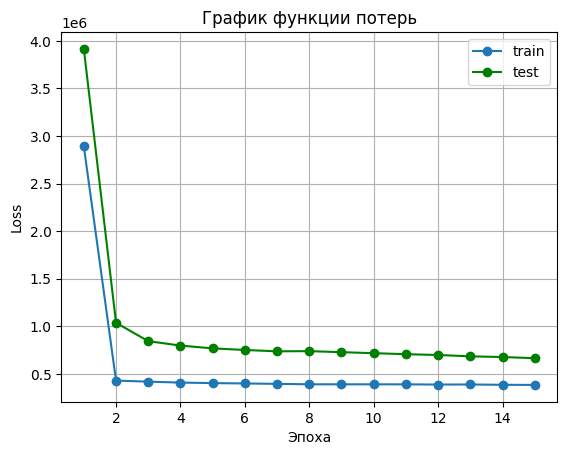

In [16]:
plt.plot(range(1, len(train_losses) + 1), train_losses, marker='o', label='train')
plt.plot(range(1, len(test_losses) + 1), test_losses, marker='o', label='test', color='green')
plt.xlabel('Эпоха')
plt.ylabel('Loss')
plt.title('График функции потерь')
plt.legend()
plt.grid(True)

# Классификация

In [17]:
from imblearn.over_sampling import SMOTE

In [18]:
df = pd.read_csv(r'../data/csgo_filetred.csv')
X = df.drop(columns=['bomb_planted'])
y = df['bomb_planted']

In [19]:
sm = SMOTE()
X_res, y_res = sm.fit_resample(X, y)
y_res.value_counts()

bomb_planted
0    98998
1    98998
Name: count, dtype: int64

In [20]:
class CsgoDataset(Dataset):
    def __init__(self, path):
        df = pd.read_csv(path)
        X = df.drop(columns=['bomb_planted'])
        y = df['bomb_planted']
        sm = SMOTE()
        self.X_res, self.y_res = sm.fit_resample(X, y)
        self.X_res = self.X_res.astype('float32').to_numpy()
        self.y_res = self.y_res.astype('int64').to_numpy()

    def __len__(self):
        return len(self.y_res)

    def __getitem__(self, idx):
        X = torch.tensor(self.X_res[idx])
        y = torch.tensor(self.y_res[idx])
        return X, y

In [21]:
csgo_ds = CsgoDataset(r'../data/csgo_filetred.csv')
csgo_ds[0]

(tensor([0.0000e+00, 1.7500e+02, 0.0000e+00, 0.0000e+00, 5.0000e+02, 5.0000e+02,
         0.0000e+00, 0.0000e+00, 4.0000e+03, 4.0000e+03, 0.0000e+00, 0.0000e+00,
         0.0000e+00, 5.0000e+00, 5.0000e+00, 0.0000e+00, 1.0000e+00, 0.0000e+00,
         0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00]),
 tensor(0))

In [22]:
train_data_csgo, test_data_csgo = random_split(csgo_ds, [0.8, 0.2])
train_dataloader_csgo = DataLoader(train_data_csgo, batch_size=batch_size)
test_dataloader_csgo = DataLoader(test_data_csgo, batch_size=batch_size)

In [23]:
class CsgoClas(nn.Module):
    def __init__(self):
        super().__init__()
        self.linear_relu_stack = nn.Sequential(
            nn.Linear(23, 64),
            nn.ReLU(),
            nn.Linear(64, 128),
            nn.ReLU(),
            nn.Linear(128, 128),
            nn.ReLU(),
            nn.Linear(128, 128),
            nn.ReLU(),
            nn.Linear(128, 2)
        )

    def forward(self, x):
        logits = self.linear_relu_stack(x)
        return logits

In [24]:
model_cs = CsgoClas()
model_cs.to(device)

CsgoClas(
  (linear_relu_stack): Sequential(
    (0): Linear(in_features=23, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=128, bias=True)
    (5): ReLU()
    (6): Linear(in_features=128, out_features=128, bias=True)
    (7): ReLU()
    (8): Linear(in_features=128, out_features=2, bias=True)
  )
)

In [25]:
learning_rate = 1e-3
epochs = 10

In [26]:
train_losses = []
test_losses = []

In [27]:
def train_loop(dataloader, model, loss_fn, optimizer):
    size = len(dataloader.dataset)
    model.train()
    batch_losses = []
    for batch, (X, y) in enumerate(dataloader):
        X, y = X.to(device), y.to(device)
        pred = model(X)
        loss = loss_fn(pred, y)
        batch_losses.append(loss.item())
        
        loss.backward()
        optimizer.step()
        optimizer.zero_grad()

        if batch % 100 == 0:
            loss, current = loss.item(), batch * batch_size + len(X)
            print(f"loss: {loss:>7f} [{current:>5d}/{size:>5d}]")
    train_losses.append(sum(batch_losses) / len(batch_losses))

In [28]:
def test_loop(dataloader, model, loss_fn):
    model.eval()
    all_targets = []
    all_pred = []
    num_butch = len(dataloader)
    size = len(dataloader.dataset)
    test_loss, correct = 0, 0
    batch_losses = []
    with torch.no_grad():
        for X, y in dataloader:
            X, y = X.to(device), y.to(device)
            pred = model(X)
            all_pred.extend(pred.argmax(1).cpu())
            all_targets.extend(y.cpu())
            test_loss += loss_fn(pred, y).item()
            batch_losses.append(loss_fn(pred, y).item())
            correct += (pred.argmax(1) == y).type(torch.float).sum().item()
            
    precision = precision_score(all_targets, all_pred)
    recall = recall_score(all_targets, all_pred)
    f1 = f1_score(all_targets, all_pred)
    
    test_losses.append(sum(batch_losses) / len(batch_losses))
    test_loss /= num_butch
    correct /= size
    print(f'Test Error: \nAccuracy: {(100*correct):>0.1f}%, Precision: {precision:>0.2f}, Recall: {recall:>0.2f}, f1_score: {f1:>0.2f} | Avg loss: {test_loss:>8f}')

In [29]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model_cs.parameters(), lr=learning_rate)
epochs = 10
for t in range(epochs):
    print(f"Epoch {t+1}\n-----------------------------")
    train_loop(train_dataloader_csgo, model_cs, loss_fn, optimizer)
    test_loop(test_dataloader_csgo, model_cs, loss_fn)
print('Done!')

Epoch 1
-----------------------------
loss: 37.638950 [   64/158397]
loss: 9.953060 [ 6464/158397]
loss: 1.464464 [12864/158397]
loss: 0.723605 [19264/158397]
loss: 0.644338 [25664/158397]
loss: 0.536446 [32064/158397]
loss: 0.377592 [38464/158397]
loss: 0.898123 [44864/158397]
loss: 0.833240 [51264/158397]
loss: 0.758766 [57664/158397]
loss: 0.490091 [64064/158397]
loss: 0.591461 [70464/158397]
loss: 0.299569 [76864/158397]
loss: 0.298574 [83264/158397]
loss: 0.381452 [89664/158397]
loss: 0.303702 [96064/158397]
loss: 0.359375 [102464/158397]
loss: 0.301476 [108864/158397]
loss: 0.376111 [115264/158397]
loss: 0.345545 [121664/158397]
loss: 0.299250 [128064/158397]
loss: 0.304898 [134464/158397]
loss: 0.473807 [140864/158397]
loss: 0.459161 [147264/158397]
loss: 0.289134 [153664/158397]
Test Error: 
Accuracy: 88.9%, Precision: 0.89, Recall: 0.89, f1_score: 0.89 | Avg loss: 0.292259
Epoch 2
-----------------------------
loss: 0.272783 [   64/158397]
loss: 0.285057 [ 6464/158397]
loss: 0

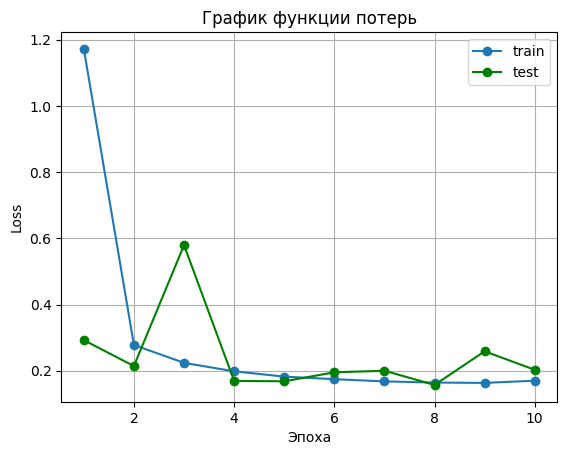

In [30]:
plt.plot(range(1, len(train_losses) + 1), train_losses, marker='o', label='train')
plt.plot(range(1, len(test_losses) + 1), test_losses, marker='o', label='test', color='green')
plt.xlabel('Эпоха')
plt.ylabel('Loss')
plt.title('График функции потерь')
plt.legend()
plt.grid(True)